# Subteam A — Preprocessing Pipeline
**Dataset:** Fruit Detection — Roboflow (fruit-detection-2aajq/fruit-nxoac)  

In [1]:
from __future__ import print_function
import cv2
import numpy as np
import matplotlib.pyplot as plt

## Step 1 Load Image

In [2]:
imagePath = "images/apple.jpg"
image = cv2.imread(imagePath)
(h, w) = image.shape[:2]
print("Image shape (H x W x Channels):", image.shape)
print("Height:", h, "| Width:", w)

Image shape (H x W x Channels): (870, 1280, 3)
Height: 870 | Width: 1280


## Step 2 — Color BGR to RGB

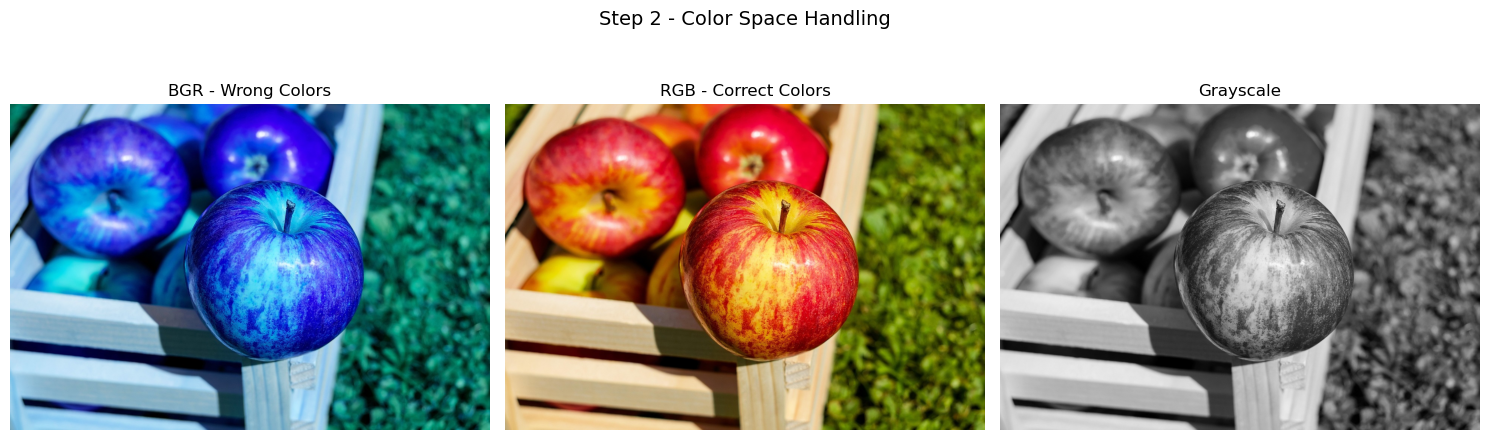

In [3]:
#from bgr to rgb
imageRGB = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

imageGray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("BGR - Wrong Colors")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(imageRGB) 
plt.title("RGB - Correct Colors")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(imageGray, cmap="gray")
plt.title("Grayscale")
plt.axis("off")

plt.suptitle("Step 2 - Color Space Handling", fontsize=14)
plt.tight_layout()
plt.savefig("step2_color_space.png")
plt.show()

## Step 3 — Resize While Preserving Aspect Ratio

YOLO requires all images to be 640x640. We resize while keeping the original aspect ratio and fill the empty space with gray.

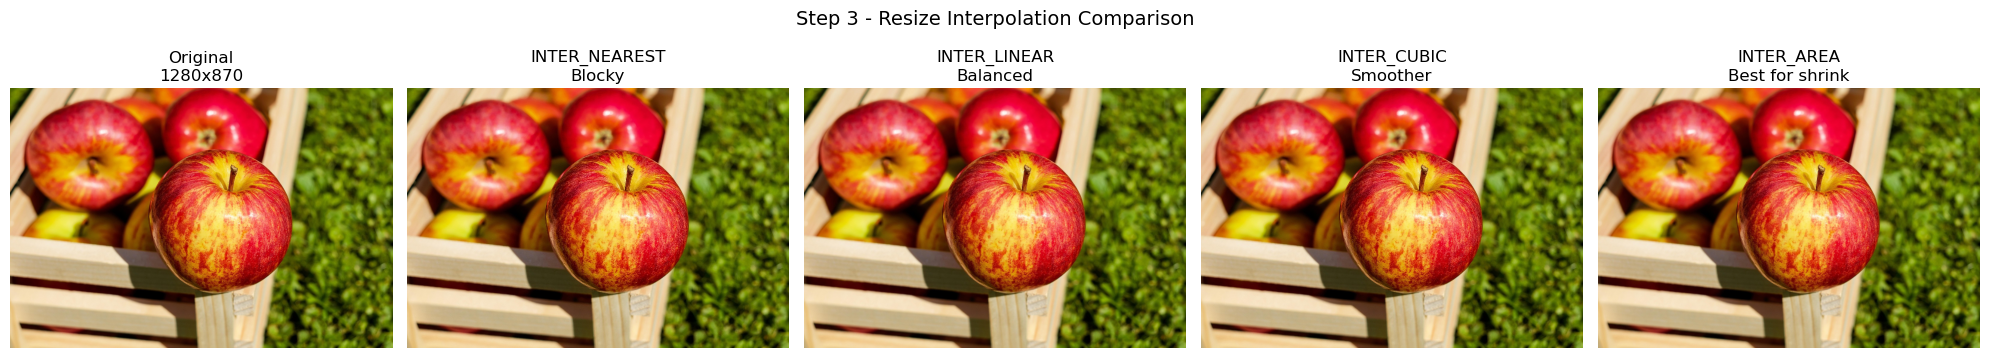

Final resized image shape: (640, 640, 3)


In [4]:
# Get original dimensions
(h, w) = image.shape[:2]

# Calculate scale to fit inside 640x640 while keeping aspect ratio
scale = 640 / max(h, w)
newW = int(w * scale)
newH = int(h * scale)
newDimension = (newW, newH)

# Resize using INTER_AREA best for shrinking
resizedImage = cv2.resize(imageRGB, newDimension, interpolation=cv2.INTER_AREA)

# Create a 640x640 gray canvas and place the resized image in the center
canvas = np.full((640, 640, 3), 114, dtype=np.uint8)
padTop  = (640 - newH) // 2
padLeft = (640 - newW) // 2
canvas[padTop:padTop + newH, padLeft:padLeft + newW] = resizedImage

# Compare all interpolation methods
resizedNearest = cv2.resize(imageRGB, newDimension, interpolation=cv2.INTER_NEAREST)
resizedLinear  = cv2.resize(imageRGB, newDimension, interpolation=cv2.INTER_LINEAR)
resizedCubic   = cv2.resize(imageRGB, newDimension, interpolation=cv2.INTER_CUBIC)
resizedArea    = cv2.resize(imageRGB, newDimension, interpolation=cv2.INTER_AREA)

# Display comparison
plt.figure(figsize=(20, 4))

plt.subplot(1, 5, 1)
plt.imshow(imageRGB)
plt.title("Original\n" + str(w) + "x" + str(h))
plt.axis("off")

plt.subplot(1, 5, 2)
plt.imshow(resizedNearest)
plt.title("INTER_NEAREST\nBlocky")
plt.axis("off")

plt.subplot(1, 5, 3)
plt.imshow(resizedLinear)
plt.title("INTER_LINEAR\nBalanced")
plt.axis("off")

plt.subplot(1, 5, 4)
plt.imshow(resizedCubic)
plt.title("INTER_CUBIC\nSmoother")
plt.axis("off")

plt.subplot(1, 5, 5)
plt.imshow(resizedArea)
plt.title("INTER_AREA\nBest for shrink")
plt.axis("off")

plt.suptitle("Step 3 - Resize Interpolation Comparison", fontsize=14)
plt.tight_layout()
plt.savefig("step3_resizing.png")
plt.show()

print("Final resized image shape:", canvas.shape)

## Step 4 — Translation

Translation moves the image by a certain number of pixels in the X and Y directions.

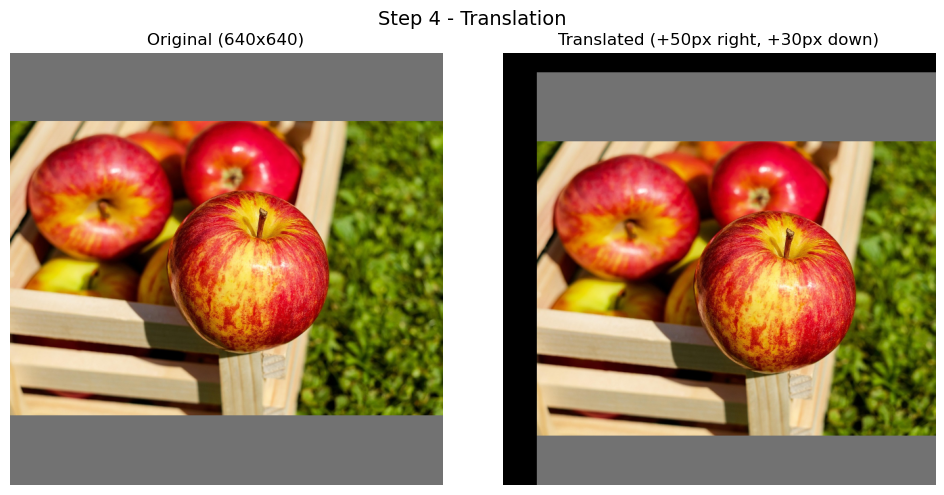

In [5]:
# Define translation matrix — move 50 pixels right and 30 pixels down
translationMatrix = np.float32([[1, 0, 50], [0, 1, 30]])

# Apply translation
translatedImage = cv2.warpAffine(canvas, translationMatrix, (canvas.shape[1], canvas.shape[0]))

# Display
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(canvas)
plt.title("Original (640x640)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(translatedImage)
plt.title("Translated (+50px right, +30px down)")
plt.axis("off")

plt.suptitle("Step 4 - Translation", fontsize=14)
plt.tight_layout()
plt.savefig("step4_translation.png")
plt.show()

## Step 5 — Noise Reduction

Apply four blurring techniques to reduce noise in fruit images.

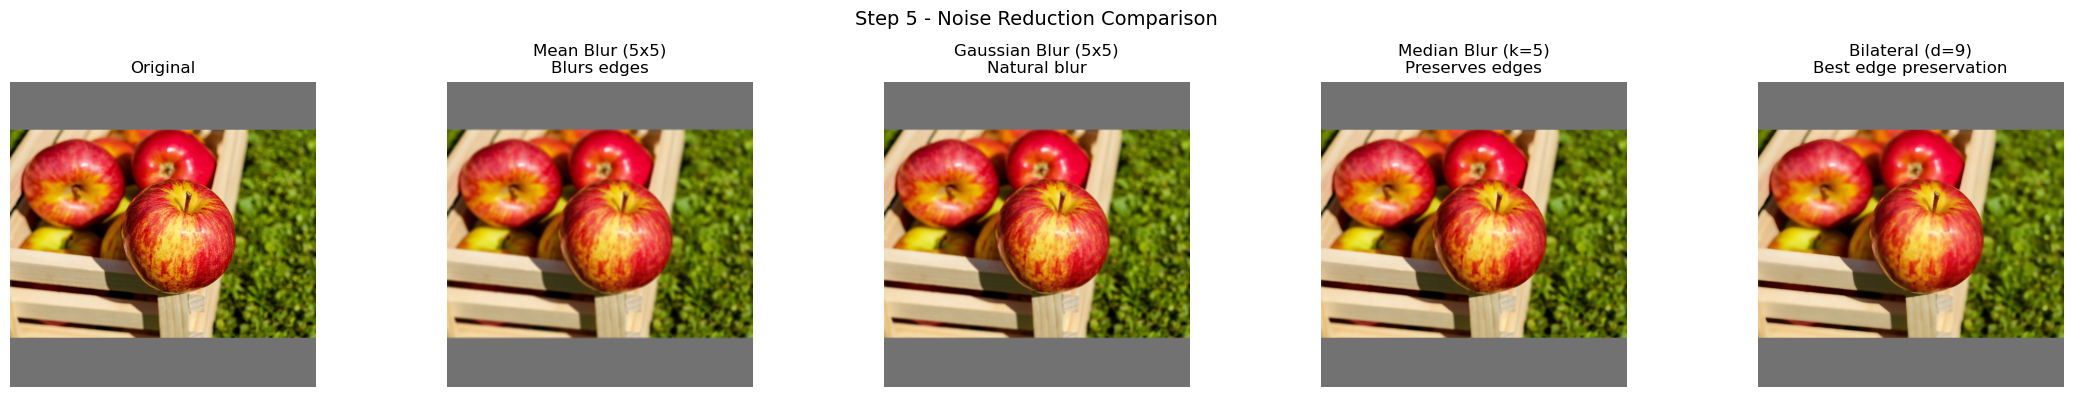

In [6]:
# Mean blur
meanBlurred = cv2.blur(canvas, (5, 5))

# Gaussian blur
gaussianBlurred = cv2.GaussianBlur(canvas, (5, 5), 0)

# Median blur
medianBlurred = cv2.medianBlur(canvas, 5)

# Bilateral filter
bilateralBlurred = cv2.bilateralFilter(canvas, 9, 75, 75)

# Display all
plt.figure(figsize=(22, 4))

plt.subplot(1, 5, 1)
plt.imshow(canvas)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 5, 2)
plt.imshow(meanBlurred)
plt.title("Mean Blur (5x5)\nBlurs edges")
plt.axis("off")

plt.subplot(1, 5, 3)
plt.imshow(gaussianBlurred)
plt.title("Gaussian Blur (5x5)\nNatural blur")
plt.axis("off")

plt.subplot(1, 5, 4)
plt.imshow(medianBlurred)
plt.title("Median Blur (k=5)\nPreserves edges")
plt.axis("off")

plt.subplot(1, 5, 5)
plt.imshow(bilateralBlurred)
plt.title("Bilateral (d=9)\nBest edge preservation")
plt.axis("off")

plt.suptitle("Step 5 - Noise Reduction Comparison", fontsize=14)
plt.tight_layout()
plt.savefig("step5_noise_reduction.png")
plt.show()

## Step 6 — Thresholding and Binarization

Thresholding converts a grayscale image to binary black and white.

Otsu threshold value: 143.0


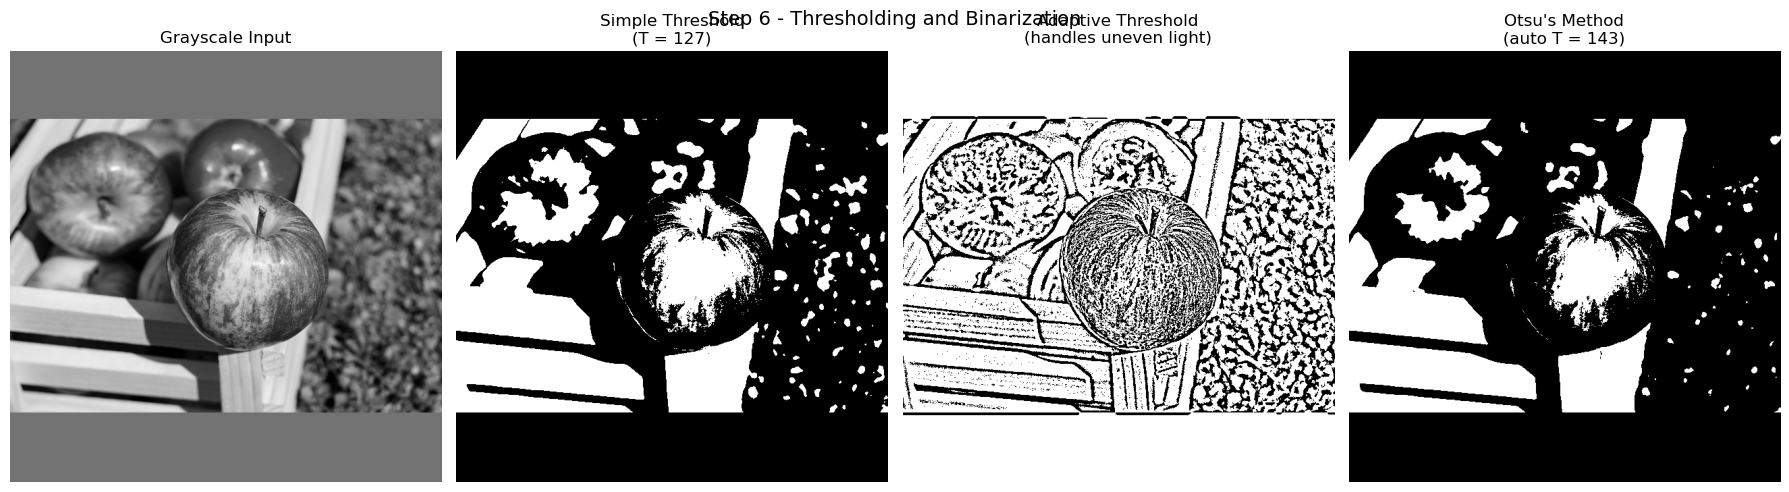

In [7]:
# Convert the resized canvas to grayscale for thresholding
canvasGray = cv2.cvtColor(canvas, cv2.COLOR_RGB2GRAY)

# Simple thresholding
(T, binarizedSimple) = cv2.threshold(canvasGray, 127, 255, cv2.THRESH_BINARY)

# Adaptive thresholding Gaussian
binarizedAdaptive = cv2.adaptiveThreshold(
    canvasGray, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11, 2
)

# Otsu's binarization
(T_otsu, binarizedOtsu) = cv2.threshold(
    canvasGray, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)
print("Otsu threshold value:", T_otsu)

# Display all
plt.figure(figsize=(18, 5))

plt.subplot(1, 4, 1)
plt.imshow(canvasGray, cmap="gray")
plt.title("Grayscale Input")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(binarizedSimple, cmap="gray")
plt.title("Simple Threshold\n(T = 127)")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(binarizedAdaptive, cmap="gray")
plt.title("Adaptive Threshold\n(handles uneven light)")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(binarizedOtsu, cmap="gray")
plt.title("Otsu's Method\n(auto T = " + str(int(T_otsu)) + ")")
plt.axis("off")

plt.suptitle("Step 6 - Thresholding and Binarization", fontsize=14)
plt.tight_layout()
plt.savefig("step6_thresholding.png")
plt.show()

## Step 7 — Histogram Visualization

A histogram shows the frequency of each pixel intensity 0-255 in an image.
Histograms help us understand the brightness and color distribution of our dataset, and verify that preprocessing did not cause unwanted shifts in intensity.

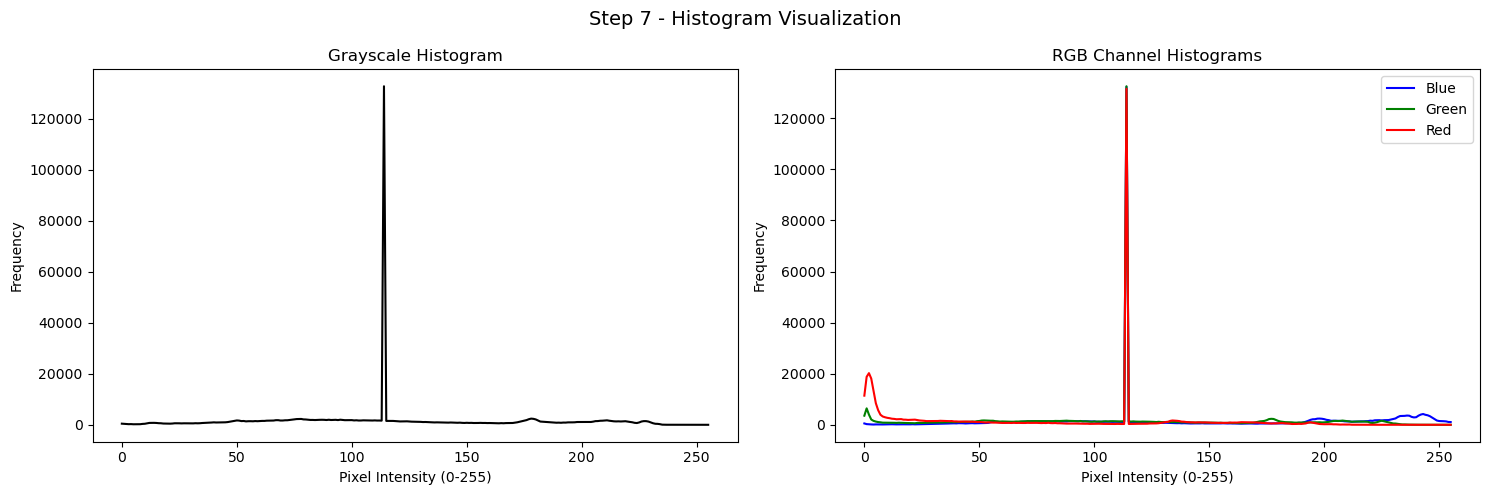

In [8]:
# Calculate histogram for grayscale image
grayHist = cv2.calcHist([canvasGray], [0], None, [256], [0, 256])

# Calculate histogram for each color channel BGR
blueHist  = cv2.calcHist([canvas], [0], None, [256], [0, 256])
greenHist = cv2.calcHist([canvas], [1], None, [256], [0, 256])
redHist   = cv2.calcHist([canvas], [2], None, [256], [0, 256])

# Display histograms
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.plot(grayHist, color="black")
plt.title("Grayscale Histogram")
plt.xlabel("Pixel Intensity (0-255)")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.plot(blueHist,  color="blue",  label="Blue")
plt.plot(greenHist, color="green", label="Green")
plt.plot(redHist,   color="red",   label="Red")
plt.title("RGB Channel Histograms")
plt.xlabel("Pixel Intensity (0-255)")
plt.ylabel("Frequency")
plt.legend()

plt.suptitle("Step 7 - Histogram Visualization", fontsize=14)
plt.tight_layout()
plt.savefig("step7_histogram.png")
plt.show()

## Step 8 — Sharpening Filter

A sharpening filter enhances edges by emphasizing the center pixel and subtracting surrounding neighbors.

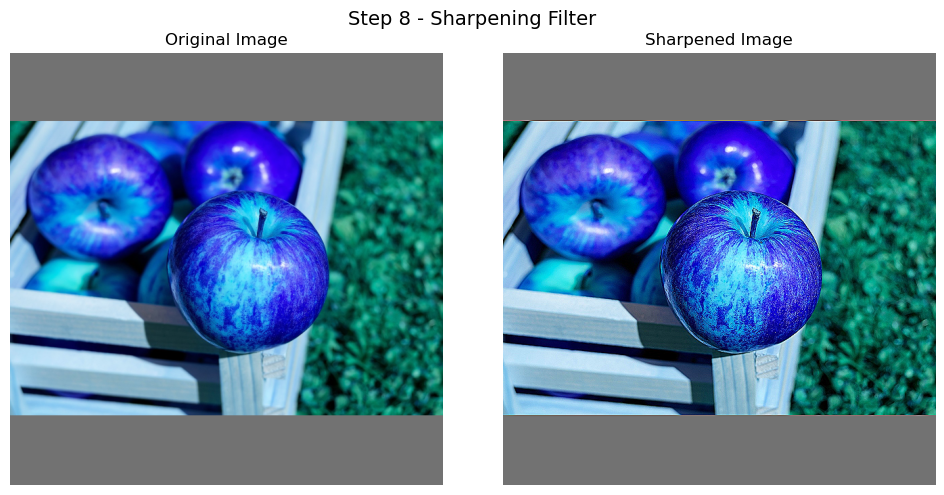

In [9]:
# Define kernel
sharpeningKernel = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
])

# Apply the sharpening filter
sharpenedImage = cv2.filter2D(canvas, -1, sharpeningKernel)

# Display before and after
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(sharpenedImage, cv2.COLOR_BGR2RGB))
plt.title("Sharpened Image")
plt.axis("off")

plt.suptitle("Step 8 - Sharpening Filter", fontsize=14)
plt.tight_layout()
plt.savefig("step8_sharpening.png")
plt.show()